# 0 · The dataset

**Run this first.** It builds the one set every other notebook trains on and is scored on, so that every model's
result can be set beside every other's.

An upscaler learns from pairs: the small, damaged picture a client receives (**LR**) and the clean picture it came from
(**HR**). The host shrinks its screen by 2, converts it to 4:2:0 and encodes it with H.264, through one of its two lines:
**x264** (`ultrafast`, no loop filter) or **NVENC** (the loop filter on). So every source here is made a short clip and
sent through both lines at six bitrates, and patches are cut from the decoded frames.

**The sources** (downloaded by `datasets/download.py`, drawn by `datasets/screens.py`):

- **Video**: YouTube sequences, 32 frames each, that are clean and detailed: cheap to code (median QP under 18 at
  0.26 bits per pixel, unshrunk) and detailed at the finest scale (halved and restored with bicubic, 44 dB or less).
  Up to three a video, spread over it.
- **Screens**: desktop screens drawn in real fonts (code, documents, terminals, spreadsheets, chat, file explorers,
  settings; light and dark; 100–200% display scale), two sets from different seeds. Your own screenshots in
  `datasets/raw/captures/` join them, if there are any.
- **Photos**: DIV2K and Flickr2K.

A still picture becomes a 32-frame clip at 30 fps of a 1920×1080 or 1280×720 window sliding, zooming or standing still
over it (`helpers/motion.py`): a stream is mostly moving frames, and the codec damages them differently from a still.

**The pairs.** For each source and line: the stream at 0.25, 0.5, 1, 2, 4 and 8 Mbit/s, and the slice header of every
frame (what a client can read: the slice QP, whether the loop filter runs, I or P frame). Then one settled P frame in
each slice QP bin (0-18, 18-26, ... 46-52) and one I frame, from whichever stream gave it, and 4 patches of each: a
72 px LR input (a 64 px core and a halo of 4) over its 128 px HR target, skipping flat spots and spots the codec
destroyed. Every patch keeps its labels: slice QP, loop filter, I frame, encoder, and its kind (video, screen, photo).

**Three splits, by source**, never by patch (patches of one picture look alike):

- **train**: what models learn from;
- **select**: 5% of the training videos and pictures, held out, to choose each training's best epoch;
- **val**: YouTube-8M's test videos, the screens drawn for testing, DIV2K's validation photos. Only ever scored, at the
  end, the same way for every model.

**Limits.** NVENC reads frames swscale shrank with bicubic, where the host's NVENC line shrinks on the GPU. The screens
are drawn, and a picture moved by whole pixels is not every motion a desktop makes.

```
uv run datasets/download.py div2k flickr2k
uv run datasets/download.py yt8m-videos --total 1000 --sequences 5
uv run datasets/screens.py
uv run datasets/screens.py --seed 1 --name screens-s1 --train 600 --test 120
```

Needs an NVIDIA GPU with NVENC. Writes the set into `datasets/upscale/` (`training.DATA_DIR`), with a `manifest.json`.

In [1]:
"""Settings."""

import json
import os
import re
import shutil
import time
import zlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from threading import BoundedSemaphore

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

os.environ["DATASETS_DIR"] = "/mnt/d/datasets"   # where the datasets are: set before helpers is imported

from helpers import degrade, metrics, models, motion, patches, sources, training
from helpers.training import DEVICE

OUT_DIR = training.DATA_DIR           # datasets/upscale/: what every notebook reads
TARGETS_FILE = OUT_DIR / "targets.csv"   # each YouTube sequence's test as a target, measured once
PARTS_DIR = OUT_DIR / "_parts"        # one file a source while the set is made, so a run resumes; removed at the end

# the sources
SIZES = ((1920, 1080), (1280, 720))   # a clip's size before the x2: a video's largest it fills, an image's at random
CLIP_FRAMES, SETTLE = 32, 8           # frames a clip; frames left out at its start while the rate control settles
VIDEO_CLIPS_PER_VIDEO = 3             # targets a video, at most, spread over it
REFERENCE_BPP, SCORE_EVERY = 0.26, 10              # a video target's test: its median QP at this rate, unshrunk...
TARGET_MAX_QP, TARGET_MAX_ROUND_TRIP_DB = 18, 44   # ...under 18, and a bicubic round trip of 44 dB or less
IMAGES = {                            # files a split, None for all; "val" reads a dataset's test.txt
    "screens": {"train": None, "val": None},       # datasets/screens.py
    "screens-s1": {"train": None, "val": None},    # datasets/screens.py --seed 1 --name screens-s1
    "div2k": {"train": 250, "val": 60},
    "flickr2k": {"train": 150},
}
CAPTURES = sources.RAW / "captures"   # your own screenshots: a screen each, every fifth one validation
IMAGE_FPS = 30
KINDS = ("video", "screen", "photo")
SELECT_SHARE = 0.05                   # training videos and pictures held out to choose best epochs

# the pairs
SCALE = 2
PAIR_MBPS = (0.25, 0.5, 1, 2, 4, 8)              # streams to find frames of each QP bin in
QP_EDGES = (0, 18, 26, 30, 34, 38, 42, 46, 52)   # bins of the slice QP
FRAMES_PER_BIN, INTRA_FRAMES = 1, 1              # a source and line: P frames in each bin, I frames in all
PATCHES_PER_FRAME, PATCH_HR, HALO = 4, 128, 4
VAR_MIN, MIN_LR_PSNR = 24.0, 22.0                # skip flat spots, and spots with nothing of the target left
WORKERS, MEASURE_WORKERS, NVENC_AT_ONCE = 12, 8, 6   # the 3090's driver runs 8 NVENC sessions at once: leave two

LUMA = np.array([0.2126, 0.7152, 0.0722], np.float32)
PARTS_DIR.mkdir(parents=True, exist_ok=True)
print("datasets", sources.ROOT, " output", OUT_DIR, " device", DEVICE)

datasets /mnt/d/datasets  output /mnt/d/datasets/upscale  device cuda


## 1. Video targets

Every sequence of every video is tested once and the result cached in `TARGETS_FILE` (a sequence too small or too
short gets an empty row). Of a video's sequences that pass, up to `VIDEO_CLIPS_PER_VIDEO`, spread over it.

In [2]:
MIX = Path(sources.__file__).resolve().parents[3] / "datasets" / "yt8m-mix.txt"


def video_groups():
    """Category folder -> its group, from the sections of the mix file."""
    major = minor = None
    groups = {}
    for line in MIX.read_text(encoding="utf-8").splitlines():
        if heading := re.match(r"# == (\w+)", line):
            major = heading[1]
        elif heading := re.match(r"# -- (.+?) - [\d.]+", line):
            minor = heading[1]
        elif entry := re.match(r"[\d.]+\s+(.+?)\s*$", line):
            folder = re.sub(r"[^\w-]+", "_", entry[1]).strip("_")
            groups[folder] = "camera footage" if major == "Other" else minor.lower()
    return groups


def frames_of(path):
    """A sequence's first `CLIP_FRAMES` frames, centre-cropped to the largest of `SIZES` it fills, and its frame rate."""
    frames, fps = sources.load_sequence(path)
    frames = frames[:CLIP_FRAMES]
    size = next((s for s in SIZES if frames.shape[2] >= s[0] and frames.shape[1] >= s[1]), None)
    if size is None or len(frames) < CLIP_FRAMES:
        return None, fps
    top, left = (frames.shape[1] - size[1]) // 4 * 2, (frames.shape[2] - size[0]) // 4 * 2
    return frames[:, top:top + size[1], left:left + size[0]], fps


def round_trip_db(frames):
    """Luma PSNR of frames halved and restored with bicubic, the median: high means soft."""
    luma = torch.from_numpy(frames[SETTLE::SCORE_EVERY].astype(np.float32) @ LUMA)[:, None]
    back = F.interpolate(F.interpolate(luma, scale_factor=0.5, mode="area"), size=luma.shape[2:], mode="bicubic", align_corners=False)
    mse = ((back - luma) ** 2).mean((1, 2, 3)).clamp(min=1e-6)
    return float((10 * torch.log10(255 ** 2 / mse)).median())


def target_row(clip):
    """A sequence's median QP at `REFERENCE_BPP`, unshrunk, and its round trip in dB; empty if too small or short."""
    frames, fps = frames_of(clip["path"])
    if frames is None:
        return {"key": clip["key"], "reference_qp": np.nan, "round_trip_db": np.nan}
    made = degrade.Degradation(scale=1, bpp=REFERENCE_BPP, fps=fps, filter="bicubic", deblock=False)
    (report, _), = degrade.encode_reports(frames, [made])
    qp = np.median([row["qp"] for row in report if row["type"] == "P" and row["frame"] >= SETTLE])
    return {"key": clip["key"], "reference_qp": float(qp), "round_trip_db": round_trip_db(frames)}


groups = video_groups()
sequences = []
for split, listing in (("train", "train"), ("val", "test")):
    for path in sources.files("yt8m-videos", listing):
        category, video = path.parts[-3:-1]
        sequences.append({"key": f"yt8m-videos/{video}/{path.stem}", "dataset": "yt8m-videos", "kind": "video",
                          "category": category, "group": groups.get(category, "other"), "unit": video,
                          "split": split, "path": path})

if not TARGETS_FILE.exists():
    pd.DataFrame(columns=["key", "reference_qp", "round_trip_db"]).to_csv(TARGETS_FILE, index=False)
measured_keys = set(pd.read_csv(TARGETS_FILE)["key"])
todo = [clip for clip in sequences if clip["key"] not in measured_keys]
print(f"{len(sequences)} sequences of {len({c['unit'] for c in sequences})} videos; {len(todo)} to measure")
start = time.time()
with ThreadPoolExecutor(MEASURE_WORKERS) as pool:
    for first in range(0, len(todo), 200):
        rows = list(pool.map(target_row, todo[first:first + 200]))
        pd.DataFrame(rows).to_csv(TARGETS_FILE, mode="a", header=False, index=False)
        print(f"  {first + len(rows)} of {len(todo)}, {time.time() - start:.0f} s")

measured = pd.read_csv(TARGETS_FILE).drop_duplicates("key").set_index("key")
passes = set(measured.index[(measured["reference_qp"] < TARGET_MAX_QP) & (measured["round_trip_db"] <= TARGET_MAX_ROUND_TRIP_DB)])
by_video = {}
for clip in sequences:
    if clip["key"] in passes:
        by_video.setdefault(clip["unit"], []).append(clip)
video_targets = []
for video, clips in sorted(by_video.items()):
    clips = sorted(clips, key=lambda c: c["key"])
    step = max(1, len(clips) // VIDEO_CLIPS_PER_VIDEO)
    video_targets += clips[step // 2::step][:VIDEO_CLIPS_PER_VIDEO]
print(f"{len(passes)} of {len(measured)} sequences pass; {len(video_targets)} targets from "
      f"{len({c['unit'] for c in video_targets})} videos")

5000 sequences of 1000 videos; 0 to measure
1840 of 5000 sequences pass; 1396 targets from 612 videos


## 2. Screens, photos, and the splits

Every drawn screen, a sample of the photos and any screenshots of your own. Then the select split: 5% of the training
videos and pictures, by a fixed seed. A video's sequences all go one way.

In [3]:
pick = np.random.default_rng(0)
image_sources = []
for dataset, wanted in IMAGES.items():
    kind = "screen" if dataset.startswith("screens") else "photo"
    drawn = {}
    if kind == "screen":
        drawn = {row["file"]: row["kind"] for row in json.loads((sources.RAW / dataset / "screens.json").read_text(encoding="utf-8"))}
    for split, count in wanted.items():
        paths = sources.files(dataset, "test" if split == "val" else "train")
        if count is not None and count < len(paths):
            paths = [paths[i] for i in sorted(pick.choice(len(paths), count, replace=False))]
        for path in paths:
            name = path.relative_to(sources.RAW / dataset).as_posix()
            image_sources.append({"key": f"{dataset}/{name}", "dataset": dataset, "kind": kind,
                                  "group": f"{kind}: {drawn.get(name, dataset)}", "split": split, "path": path})
for path in sorted(p for p in CAPTURES.rglob("*") if p.suffix.lower() in (".png", ".jpg", ".jpeg", ".bmp", ".webp")):
    name = path.relative_to(CAPTURES).as_posix()
    image_sources.append({"key": f"captures/{name}", "dataset": "captures", "kind": "screen", "group": "screen: capture",
                          "split": "val" if zlib.crc32(name.encode()) % 5 == 0 else "train", "path": path})
for source in image_sources:
    source["unit"] = source["key"]
    source.setdefault("category", source["group"])
for source in video_targets:
    source["group"] = f"video: {source['group']}"

everything = video_targets + image_sources
units = sorted({s["unit"] for s in everything if s["split"] == "train"})
held = set(np.random.default_rng(0).permutation(units)[:round(SELECT_SHARE * len(units))])
for source in everything:
    if source["split"] == "train" and source["unit"] in held:
        source["split"] = "select"

counts = pd.DataFrame([{"kind": s["kind"], "content": s["group"], "split": s["split"]} for s in everything])
print(counts.pivot_table(index=["kind", "content"], columns="split", aggfunc="size", fill_value=0)[["train", "select", "val"]].to_string())
print(f"\n{len(everything)} sources")

split                                     train  select  val
kind   content                                              
photo  photo: div2k                         235      15   60
       photo: flickr2k                      142       8    0
screen screen: desktop                      413      18   67
       screen: page                         543      26  133
video  video: 2d, retro and casual games     34       0    6
       video: animation                     128      10   20
       video: camera footage                158       8   27
       video: console and general games      72       7   11
       video: creative software              79       0   15
       video: desktop and software use      260      16   37
       video: live action                   149       4   15
       video: music and live                 39       1    5
       video: pc games                      194       9   27
       video: phones and tablets             52       7    6

3056 sources


## 3. Pairs

For each source and line, the six streams and the slice header of every frame; one settled P frame of each slice QP
bin and one I frame, from whichever stream gave it; and 4 patches of each. The streams are made by
`degrade.degrade_many`, which reads and writes files in memory rather than pipes, so 12 sources run at once. One
source's patches go to `PARTS_DIR` when it is done, so a stopped run carries on where it was.

In [4]:
PATCH_LR = PATCH_HR // SCALE
INPUT_LR = PATCH_LR + 2 * HALO
QP_BINS = list(zip(QP_EDGES[:-1], QP_EDGES[1:]))
DTYPES = {"qp": np.float32, "deblocked": np.bool_, "intra": np.bool_, "encoder": np.int8, "kind": np.int8}
nvenc_sessions = BoundedSemaphore(NVENC_AT_ONCE)


def clip_of(source, rng):
    """A source's frames, their rate, and how an image was shown (None for a video, or for an image too small)."""
    if source["kind"] == "video":
        frames, fps = frames_of(source["path"])
        return frames, fps, None
    image = sources.load_image(source["path"])
    height, width = image.shape[:2]
    fits = [size for size in SIZES if width >= size[0] and height >= size[1]]
    if not fits:
        return None, IMAGE_FPS, None
    shown = motion.sample(rng, (width, height), CLIP_FRAMES, fits[int(rng.integers(len(fits)))])
    return motion.render(image, shown), IMAGE_FPS, shown


def lr_psnr(lr_core, hr_patch):
    """Luma PSNR of a stream spot against a clean downscale of its target."""
    clean = (hr_patch.astype(np.float32) @ LUMA).reshape(PATCH_LR, SCALE, PATCH_LR, SCALE).mean(axis=(1, 3))
    mse = ((lr_core.astype(np.float32) @ LUMA - clean) ** 2).mean()
    return 10 * np.log10(255 ** 2 / max(mse, 1e-10))


def spots(hr, lr, rng):
    """Up to `PATCHES_PER_FRAME` (LR with its halo, HR) of one frame, not flat and not destroyed."""
    out = []
    for _ in range(4 * PATCHES_PER_FRAME):
        if len(out) == PATCHES_PER_FRAME:
            break
        y, x = (2 * int(rng.integers(0, (size - INPUT_LR) // 2 + 1)) for size in lr.shape[:2])   # even pixels: 4:2:0
        y_hr, x_hr = (y + HALO) * SCALE, (x + HALO) * SCALE
        hr_patch, lr_patch = hr[y_hr:y_hr + PATCH_HR, x_hr:x_hr + PATCH_HR], lr[y:y + INPUT_LR, x:x + INPUT_LR]
        if (hr_patch.astype(np.float32) @ LUMA).var() >= VAR_MIN and lr_psnr(lr_patch[HALO:-HALO, HALO:-HALO], hr_patch) >= MIN_LR_PSNR:
            out.append((lr_patch.copy(), hr_patch.copy()))
    return out


def streams_of(frames, fps, encoder):
    """{mbps: (Degradation, LR, report)} of one line at every bitrate of `PAIR_MBPS`."""
    lr_width, lr_height = degrade.stream_size(*degrade.crop(frames, SCALE).shape[2:0:-1], SCALE)
    made = [degrade.Degradation(scale=SCALE, bpp=mbps * 1e6 / (lr_width * lr_height * fps), fps=fps,
                                filter="bicubic", deblock=False, encoder=encoder) for mbps in PAIR_MBPS]
    if encoder == "nvenc":
        with nvenc_sessions:
            streams = degrade.degrade_many(frames, made)
    else:
        streams = degrade.degrade_many(frames, made)
    return {mbps: (d, lr, report) for mbps, d, (lr, _, report) in zip(PAIR_MBPS, made, streams)}


def part_path(source):
    return PARTS_DIR / (source["key"].replace("/", "__") + ".npz")


def make_part(source):
    """Write one source's patches and labels to its part file; return None, or what went wrong."""
    path = part_path(source)
    if path.exists():
        return None
    try:
        rng = np.random.default_rng(zlib.crc32(source["key"].encode()))
        frames, fps, shown = clip_of(source, rng)
        out = {"lr": [], "hr": [], **{name: [] for name in DTYPES}}
        entries = []
        hr = degrade.crop(frames, SCALE) if frames is not None else None
        for e, encoder in enumerate(degrade.ENCODERS if frames is not None else ()):
            streams = streams_of(frames, fps, encoder)
            found = {qp_bin: [] for qp_bin in QP_BINS} | {"intra": []}
            for mbps, (_, _, report) in streams.items():
                for row in report:
                    if row["type"] == "I":
                        found["intra"].append((mbps, row))
                    elif row["frame"] >= SETTLE:
                        for low, high in QP_BINS:
                            if low <= row["slice_qp"] < high:
                                found[low, high].append((mbps, row))
            chosen = {}
            for key, candidates in found.items():
                keep = INTRA_FRAMES if key == "intra" else FRAMES_PER_BIN
                for i in rng.permutation(len(candidates))[:keep]:
                    mbps, row = candidates[i]
                    chosen.setdefault(mbps, []).append(row)
            for mbps, rows in sorted(chosen.items()):
                made, lr, _ = streams[mbps]
                first = len(out["lr"])
                for row in rows:
                    for lr_patch, hr_patch in spots(hr[row["frame"]], lr[row["frame"]], rng):
                        out["lr"].append(lr_patch)
                        out["hr"].append(hr_patch)
                        out["qp"].append(row["slice_qp"])
                        out["deblocked"].append(row["deblocked"])
                        out["intra"].append(row["type"] == "I")
                        out["encoder"].append(e)
                        out["kind"].append(KINDS.index(source["kind"]))
                if len(out["lr"]) > first:
                    entries.append({"key": source["key"], "dataset": source["dataset"], "kind": source["kind"],
                                    "group": source["group"], "mbps": mbps, "encoder": encoder,
                                    "patches": [first, len(out["lr"])], "degradation": made.as_dict(),
                                    **({"motion": shown.as_dict()} if shown is not None else {})})
            del streams
        arrays = {"lr": np.array(out["lr"], np.uint8).reshape(-1, INPUT_LR, INPUT_LR, 3),
                  "hr": np.array(out["hr"], np.uint8).reshape(-1, PATCH_HR, PATCH_HR, 3),
                  **{name: np.array(out[name], dtype) for name, dtype in DTYPES.items()}}
        partial = path.with_name(path.name + ".tmp")
        with open(partial, "wb") as file:
            np.savez(file, **arrays, sources=np.array(json.dumps(entries)))
        os.replace(partial, path)   # a part is whole or not there
        return None
    except Exception as error:   # one bad source is reported, not the end of the run
        return f"{source['key']}: {error}"


todo = [s for s in everything if not part_path(s).exists()]
print(f"{len(everything) - len(todo)} sources done before, {len(todo)} to do")
start, failed = time.time(), []
with ThreadPoolExecutor(WORKERS) as pool:
    for done, error in enumerate(pool.map(make_part, todo), 1):
        if error:
            failed.append(error)
        if done % 250 == 0 or done == len(todo):
            print(f"  {done} of {len(todo)}, {time.time() - start:.0f} s")
print(f"{len(failed)} failed" + "".join(f"\n  {line}" for line in failed[:20]))

0 sources done before, 3056 to do
  250 of 3056, 310 s
  500 of 3056, 606 s
  750 of 3056, 897 s
  1000 of 3056, 1211 s
  1250 of 3056, 1523 s
  1500 of 3056, 1842 s
  1750 of 3056, 2176 s
  2000 of 3056, 2504 s
  2250 of 3056, 2841 s
  2500 of 3056, 3174 s
  2750 of 3056, 3472 s
  3000 of 3056, 3763 s
  3056 of 3056, 3821 s
0 failed


## 4. Save

The parts, in the order of `everything`, become one array a field and split, written straight to disk (the training
split is several GB); then the manifest, and the parts go. LR and HR are `uint8` arrays shaped `(patches, 1, h, w, 3)`,
which `helpers/patches.py` reads.

In [5]:
def write_npy(file, dtype, shape):
    """Open `file` as an .npy of this dtype and shape whose data is then written in order."""
    out = open(file, "wb")
    np.lib.format.write_array_header_1_0(out, {"descr": np.dtype(dtype).str, "fortran_order": False, "shape": shape})
    return out


if failed:
    raise RuntimeError(f"{len(failed)} sources failed - run the cell above again")
splits = {}
for split in ("train", "select", "val"):
    members = [s for s in everything if s["split"] == split]
    sizes = []
    for source in members:
        with np.load(part_path(source)) as part:
            sizes.append(len(part["kind"]))
    total = sum(sizes)
    lr_file = write_npy(OUT_DIR / f"{split}_lr.npy", np.uint8, (total, 1, INPUT_LR, INPUT_LR, 3))
    hr_file = write_npy(OUT_DIR / f"{split}_hr.npy", np.uint8, (total, 1, PATCH_HR, PATCH_HR, 3))
    labels, entries, at = {name: [] for name in DTYPES}, [], 0
    for source, size in zip(members, sizes):
        with np.load(part_path(source)) as part:
            lr_file.write(np.ascontiguousarray(part["lr"]).tobytes())
            hr_file.write(np.ascontiguousarray(part["hr"]).tobytes())
            for name in DTYPES:
                labels[name].append(part[name])
            entries += [{**entry, "patches": [entry["patches"][0] + at, entry["patches"][1] + at]}
                        for entry in json.loads(str(part["sources"]))]
        at += size
    lr_file.close()
    hr_file.close()
    for name, dtype in DTYPES.items():
        np.save(OUT_DIR / f"{split}_{name}.npy", np.concatenate(labels[name]).astype(dtype))
    splits[split] = {"patches": total, "lr": f"{split}_lr.npy", "hr": f"{split}_hr.npy",
                     **{name: f"{split}_{name}.npy" for name in DTYPES}, "sources": entries}
    print(f"{split:<7}{total:7} patches from {len({e['key'] for e in entries})} of {len(members)} sources")

manifest = {"created": time.strftime("%Y-%m-%dT%H:%M:%S"), "scale": SCALE, "patch_lr": PATCH_LR, "patch_hr": PATCH_HR,
            "halo": HALO, "input_lr": INPUT_LR, "frames_per_patch": 1, "encoders": list(degrade.ENCODERS),
            "kinds": list(KINDS), "qp_edges": list(QP_EDGES), "splits": splits}
(OUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=1), encoding="utf-8")
shutil.rmtree(PARTS_DIR)
written = sum((OUT_DIR / f"{split}_{part}.npy").stat().st_size for split in splits for part in ("lr", "hr"))
print(f"{written / 1e9:.1f} GB written to {OUT_DIR}")

train   140795 patches from 2476 of 2498 sources
select    6982 patches from 126 of 129 sources
val      24286 patches from 426 of 429 sources
11.1 GB written to /mnt/d/datasets/upscale


## 5. Checks

What each split holds, by kind; then bicubic against the target on the validation split, by kind, line and slice QP
bin, which must fall as the QP rises or the label means nothing; then a few pairs, to see that LR and HR show the same
spot.

In [6]:
manifest = training.load_manifest(OUT_DIR)
labels = {split: {name: np.load(OUT_DIR / manifest["splits"][split][name]) for name in DTYPES} for split in manifest["splits"]}
rows = []
for split, lab in labels.items():
    for k, kind in enumerate(KINDS):
        mine = lab["kind"] == k
        rows.append({"split": split, "kind": kind, "patches": int(mine.sum()), "share": f"{mine.mean():.0%}",
                     "sources": len({e["key"] for e in manifest["splits"][split]["sources"] if e["kind"] == kind}),
                     "NVENC": f"{(lab['encoder'][mine] == 1).mean():.0%}", "I frames": f"{lab['intra'][mine].mean():.0%}",
                     "slice QP 38+": f"{(lab['qp'][mine] >= 38).mean():.0%}"})
print(pd.DataFrame(rows).to_string(index=False))

 split   kind  patches share  sources NVENC I frames slice QP 38+
 train  video    65227   46%     1165   50%      14%          20%
 train screen    52865   38%      941   52%      13%          26%
 train  photo    22703   16%      370   52%      13%          30%
select  video     3261   47%       62   50%      15%          18%
select screen     2393   34%       42   51%      13%          25%
select  photo     1328   19%       22   53%      13%          29%
   val  video     9416   39%      169   49%      14%          19%
   val screen    11199   46%      197   51%      13%          26%
   val  photo     3671   15%       60   52%      12%          31%


In [7]:
val_lr, val_hr = patches.load(OUT_DIR, "val", manifest)
val = labels["val"]


def to_tensor(images):
    return torch.from_numpy(np.array(images)).to(DEVICE).permute(0, 3, 1, 2).float() / 255


@torch.no_grad()
def bicubic_ssim(members):
    """Mean SSIM-Y of bicubic on these validation patches."""
    out = [metrics.per_image(patches.trim(models.bicubic(to_tensor(val_lr[batch]), SCALE), HALO * SCALE),
                             to_tensor(val_hr[batch]))["ssim"].cpu() for batch in np.array_split(members, max(1, len(members) // 256))]
    return float(torch.cat(out).mean())


rows = []
for k, kind in enumerate(KINDS):
    for e, encoder in enumerate(manifest["encoders"]):
        row = {"kind": kind, "line": encoder}
        for low, high in QP_BINS:
            members = np.flatnonzero((val["kind"] == k) & (val["encoder"] == e) & ~val["intra"] & (val["qp"] >= low) & (val["qp"] < high))
            row[f"{low}-{high}"] = round(bicubic_ssim(members), 4) if len(members) >= 20 else None
        row["I frames"] = round(bicubic_ssim(np.flatnonzero((val["kind"] == k) & (val["encoder"] == e) & val["intra"])), 4)
        rows.append(row)
print("bicubic SSIM-Y against the target, validation P frames by slice QP bin (blank: under 20 patches)")
print(pd.DataFrame(rows).fillna("").to_string(index=False))
print(f"\nall validation patches: {bicubic_ssim(np.arange(len(val_lr))):.4f}; "
      + ", ".join(f"{kind} {bicubic_ssim(np.flatnonzero(val['kind'] == k)):.4f}" for k, kind in enumerate(KINDS)))

bicubic SSIM-Y against the target, validation P frames by slice QP bin (blank: under 20 patches)
  kind  line   0-18  18-26  26-30  30-34  34-38  38-42  42-46  46-52  I frames
 video  x264 0.9593 0.9379 0.9118 0.8879 0.8621 0.8357 0.7893 0.7830    0.8780
 video nvenc 0.9599 0.9463 0.9287 0.9191 0.8953 0.8676 0.8452 0.8385    0.9195
screen  x264 0.9024 0.8851 0.8705 0.8504 0.8269 0.7881 0.7937 0.8004    0.8298
screen nvenc 0.8966 0.8941 0.8832 0.8633 0.8425 0.8096 0.7871 0.7552    0.8450
 photo  x264 0.8742 0.8200 0.7711 0.7316 0.6648 0.5994 0.6014 0.6088    0.6593
 photo nvenc 0.8694 0.8484 0.8104 0.7725 0.7140 0.6680 0.6214 0.6127    0.7234

all validation patches: 0.8521; video 0.9038, screen 0.8484, photo 0.7306


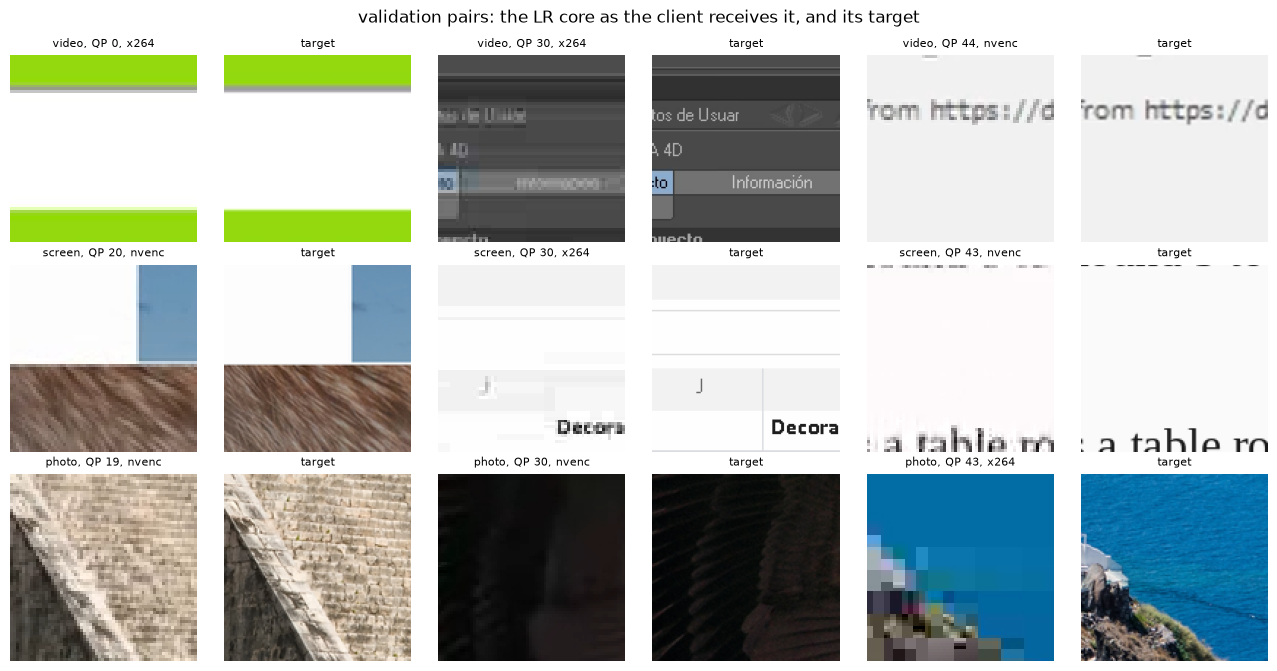

In [8]:
show = np.random.default_rng(1)
fig, axes = plt.subplots(len(KINDS), 6, figsize=(13, 6.8))
for k, kind in enumerate(KINDS):
    for column, (low, high) in enumerate(((0, 26), (30, 38), (42, 52))):
        members = np.flatnonzero((val["kind"] == k) & (val["qp"] >= low) & (val["qp"] < high))
        if not len(members):
            continue
        i = int(show.choice(members))
        axes[k, 2 * column].imshow(val_lr[i][HALO:-HALO, HALO:-HALO], interpolation="nearest")
        axes[k, 2 * column].set_title(f"{kind}, QP {val['qp'][i]:.0f}, {manifest['encoders'][val['encoder'][i]]}", fontsize=8)
        axes[k, 2 * column + 1].imshow(val_hr[i])
        axes[k, 2 * column + 1].set_title("target", fontsize=8)
for axis in axes.flat:
    axis.set_axis_off()
fig.suptitle("validation pairs: the LR core as the client receives it, and its target")
plt.tight_layout()
plt.show()

## 6. What it says

**140,795 training, 6,982 select and 24,286 validation patches**, 11.1 GB, from 3,056 sources: 1,396 YouTube targets
(1,840 of the 5,000 sequences pass the test, from 612 videos), 1,200 drawn screens and 460 photos; no screenshots of
your own yet. 22 training, 3 select and 3 validation sources gave no patch that was not flat or destroyed.

| split | patches | video | screens | photos |
| --- | --- | --- | --- | --- |
| train | 140,795 | 46% | 38% | 16% |
| select | 6,982 | 47% | 34% | 19% |
| val | 24,286 | 39% | 46% | 15% |

Half of every kind is NVENC's, about one patch in seven is from an I frame, and a fifth to a third sit at slice QP 38
and up: screens and photos reach the top bins more than video, whose targets were picked cheap to code.

**Bicubic reads 0.8521 SSIM-Y on the validation split**: video 0.9038, screens 0.8484, photos 0.7306. Within every kind
and line it falls as the slice QP rises up to 42–46, so the label means what it should; at 46–52 the screens and
photos of x264 sit a little above their 42–46 bin, likely because `MIN_LR_PSNR` drops the spots the codec destroyed
and keeps the easier ones. From QP 18–26 up, NVENC's frames are nearer the target than x264's at the same QP: its loop
filter smooths the block edges x264's `ultrafast` line leaves.

**Time**: 64 minutes for the pairs (12 sources at once), under 2 minutes to save; the targets' test is cached in
`targets.csv`.